In [44]:
# SINGLE CELL - Car Evaluation
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# 1. Load Dataset - Try 3 options (any one will work)
from google.colab import files
uplaoded = files.upload()



Saving car.csv to car.csv


In [45]:
df=pd.read_csv("car.csv")

df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc



After Encoding:
    buying  maint  doors  persons  lug_boot  safety  class
0       3      3      0        0         2       1      2
1       3      3      0        0         2       2      2
2       3      3      0        0         2       0      2
3       3      3      0        0         1       1      2
4       3      3      0        0         1       2      2

Accuracy: 0.28034682080924855

Report:
               precision    recall  f1-score   support

           0       0.31      0.31      0.31       121
           1       0.36      0.35      0.35       107
           2       0.18      0.19      0.18       118

    accuracy                           0.28       346
   macro avg       0.28      0.28      0.28       346
weighted avg       0.28      0.28      0.28       346



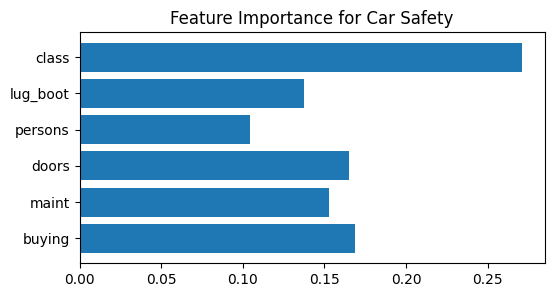

In [46]:
# 2. Pre-processing - Convert text to numbers (Label Encoding)
# Car dataset is all categorical: buying = vhigh, high, med, low etc.
le = LabelEncoder()
for col in df.columns:
    df[col] = le.fit_transform(df[col])

print("\nAfter Encoding:\n", df.head())

# 3. Features and Target - We have to predict SAFETY
# If your CSV has column 'safety' - target is safety
# If column name is different, change below
if 'safety' in df.columns:
    X = df.drop('safety', axis=1)
    y = df['safety']
else:
    # If no safety column, predict last column (class)
    X = df.iloc[:, :-1]
    y = df.iloc[:, -1]

# 4. Split + Train Random Forest
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(n_estimators=100, random_state=42) # 100 trees
model.fit(X_train, y_train)

# 5. Evaluate
y_pred = model.predict(X_test)
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nReport:\n", classification_report(y_test, y_pred))

# 6. Feature Importance - Which feature matters for safety?
plt.figure(figsize=(6,3))
plt.barh(X.columns, model.feature_importances_)
plt.title('Feature Importance for Car Safety')
plt.show()